**Variational Autoencoder for Image Generation**

Aim: To build and train a Variational Autoencoder (VAE) using PyTorch and the MNIST dataset to generate handwritten digits, compare reconstructed images with original images, and visualize the latent space

**Software Used:**
- Python
- Google Colab
- PyTorch
- Matplotlib
- MNIST Dataset

**Theory**
A Variational Autoencoder (VAE) is a generative deep learning model that learns the distribution of input data and generates new similar data.

It consists of three main components:
1. Encoder: Converts input images into mean and log variance.
2. Latent Space: Represents compressed information and samples a latent vector.
3. Decoder: Reconstructs images from the latent vector.
The VAE uses reconstruction loss and KL divergence to train the model.

**Algorithm**
1. Import the required libraries.
2. Load the MNIST dataset.
3. Build the encoder and decoder.
4. Initialize the VAE model.
5. Train the model for five epochs.
6. Calculate reconstruction loss and KL divergence.
7. Generate new handwritten digits.
8. Visualize reconstructed images and latent space.
9. Save the generated outputs.

In [1]:

import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

out = Path("lab_outputs")
out.mkdir(exist_ok=True)

print("Device:", device)


Device: cpu


In [2]:

train = datasets.MNIST(
    "data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test = datasets.MNIST(
    "data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

loader = DataLoader(
    train,
    batch_size=128,
    shuffle=True
)

print("Training images:", len(train))
print("Testing images:", len(test))


100%|██████████| 9.91M/9.91M [00:00<00:00, 63.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.70MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.13MB/s]

Training images: 60000
Testing images: 10000


In [3]:

class VAE(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )

        self.mean = nn.Linear(256, 2)
        self.logvar = nn.Linear(256, 2)

        self.decoder = nn.Sequential(
            nn.Linear(2, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)

        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

        return self.decoder(z), mu, logvar


vae = VAE().to(device)

optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=0.001
)

print(vae)


VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
  )
  (mean): Linear(in_features=256, out_features=2, bias=True)
  (logvar): Linear(in_features=256, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [4]:

for epoch in range(1, 6):

    vae.train()
    totals = dict(reconstruction=0.0, kl=0.0)

    for x, _ in loader:

        x = x.to(device)

        generated, mu, logvar = vae(x)

        recon = F.binary_cross_entropy(
            generated,
            x.flatten(1),
            reduction="sum"
        )

        kl = -0.5 * (
            1 + logvar - mu.square() - logvar.exp()
        ).sum()

        loss = (recon + kl) / x.size(0)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        totals["reconstruction"] += recon.item()
        totals["kl"] += kl.item()

    print(
        epoch,
        {
            k: round(v / len(train), 2)
            for k, v in totals.items()
        }
    )

torch.save(vae.state_dict(), out / "vae_mnist.pt")


1 {'reconstruction': 189.31, 'kl': 6.57}
2 {'reconstruction': 165.5, 'kl': 5.34}
3 {'reconstruction': 160.08, 'kl': 5.41}
4 {'reconstruction': 157.2, 'kl': 5.47}
5 {'reconstruction': 155.31, 'kl': 5.51}


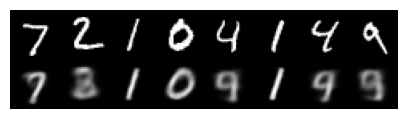

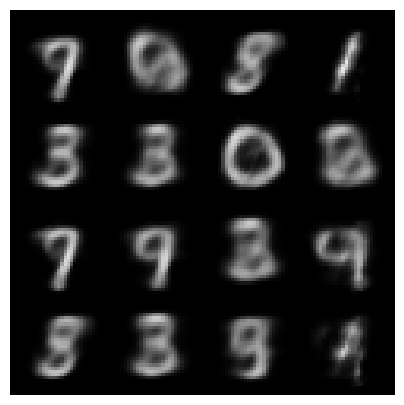

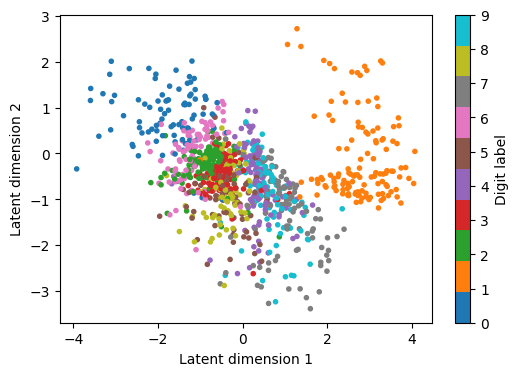

In [7]:



def show_grid(images, name, nrow=4):
    grid = make_grid(images.cpu(), nrow=nrow)

    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")

    plt.savefig(
        out / name,
        bbox_inches="tight"
    )
    plt.show()



vae.eval()

with torch.no_grad():


    x, y = next(
        iter(DataLoader(test, batch_size=1024))
    )


    mu, _ = vae.encode(x.to(device))

    recon = vae.decoder(mu[:8]).reshape(-1, 1, 28, 28)


    samples = vae.decoder(
        torch.randn(16, 2, device=device)
    )


    show_grid(
        torch.cat([x[:8], recon.cpu()]),
        "vae_reconstructed.png",
        nrow=8
    )


    show_grid(
        samples.reshape(-1, 1, 28, 28),
        "vae_generated.png"
    )

    coords = mu.cpu()


plt.figure(figsize=(6, 4))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=y,
    cmap="tab10",
    s=9
)

plt.colorbar(ticks=range(10), label="Digit label")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")

plt.savefig(
    out / "vae_latent.png",
    bbox_inches="tight"
)

plt.show()


### Result

The Variational Autoencoder (VAE) was successfully implemented using PyTorch and the MNIST dataset.

The model learned to encode handwritten digit images into a two-dimensional latent space and reconstruct them using a decoder. It also generated new handwritten digit samples using random latent vectors.

The latent space visualization showed different digit clusters, with some overlapping regions.

**Conclusion:** VAE successfully learned the underlying distribution of handwritten digits and generated new digit images.